# 1. Introduction

This project covers an analysis of episodes of the TV show The Simpsons.

Tools used include:
- pandas
- numpy
- requests
- datetime
- matplotlib

Key questions:
1. How does the viewership of The Simpsons episodes change over time?
2.  How do the IMDB ratings of The Simpsons episodes change over time?
3.  Which seasons have the highest IMDB ratings/viewerships?
4.  Which writers and directors have the highest IMDB ratings/viewerships?
5.  Do highly-rated episodes also have high viewing figures?

# 2. Data Loading

In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import requests
import datetime as dt
import matplotlib.pyplot as plt
import re
from io import StringIO

In [2]:
# Assign URLs
URL_1 = 'https://en.wikipedia.org/wiki/List_of_The_Simpsons_episodes_(seasons_1%E2%80%9320)'
URL_2 = 'https://en.wikipedia.org/wiki/List_of_The_Simpsons_episodes_(season_21%E2%80%93present)'

In [3]:
# Add User-Agent header for request
headers = {
    'User-Agent' : 'SimpsonsDataProject'
}

In [4]:
# Download webpages including User-Aget header
response_1 = requests.get(URL_1, headers = headers)
response_2 = requests.get(URL_2, headers = headers)

In [5]:
# Check if request succeeded
response_1.raise_for_status()
response_2.raise_for_status()

In [6]:
# Extract HTML tables into a list of DataFrames
episode_tables_1 = pd.read_html(StringIO(response_1.text))
episode_tables_2 = pd.read_html(StringIO(response_2.text))

In [7]:
# Verify loading
episode_tables_1[1].head()

,No. overall,No. in season,Title,Directed by,Written by,Original release date,Prod. code,U.S. viewers (millions)
0,1,1,"""Simpsons Roasting on an Open Fire""",David Silverman,Mimi Pond,"December 17, 1989[51]",7G08,26.7[52]
1,2,2,"""Bart the Genius""",David Silverman,Jon Vitti,"January 14, 1990[53]",7G02,24.5[52]
2,3,3,"""Homer's Odyssey""",Wes Archer,Jay Kogen & Wallace Wolodarsky,"January 21, 1990[54]",7G03,27.5[55]
3,4,4,"""There's No Disgrace Like Home""",Gregg Vanzo & Kent Butterworth,Al Jean & Mike Reiss,"January 28, 1990[56]",7G04,20.2[57]
4,5,5,"""Bart the General""",David Silverman,John Swartzwelder,"February 4, 1990[58]",7G05,27.1[59]


In [8]:
# Rename columns so that all tables contain consistent column titles
for i in range(2, 20):
    episode_tables_2[i] = episode_tables_2[i].rename(columns = {
        'Original release date [599]' : 'Original release date',
        'No. in season [a]' : 'No. in season',
        'Title [400]' : 'Title',
        'Original release date [400]' : 'Original release date',
    })

episode_tables_1[21] = episode_tables_1[21].rename(columns = {
    'Original release date [599]' : 'Original release date'
})

In [9]:
# Initialise episodes dataframe
episodes = pd.DataFrame()

In [10]:
# Assign data in tables to episodes dataframe and create a new column to distinguish between seasons
for i,season in enumerate(episode_tables_1[1:19] + episode_tables_1[20:22] + episode_tables_2[2:20], start = 1):
    season['Season'] = i
    episodes = pd.concat([episodes, season], ignore_index = True)

In [11]:
# Verify loading
episodes.head()

,No. overall,No. in season,Title,Directed by,Written by,Original release date,Prod. code,U.S. viewers (millions),Season
0,1.0,1.0,"""Simpsons Roasting on an Open Fire""",David Silverman,Mimi Pond,"December 17, 1989[51]",7G08,26.7[52],1
1,2.0,2.0,"""Bart the Genius""",David Silverman,Jon Vitti,"January 14, 1990[53]",7G02,24.5[52],1
2,3.0,3.0,"""Homer's Odyssey""",Wes Archer,Jay Kogen & Wallace Wolodarsky,"January 21, 1990[54]",7G03,27.5[55],1
3,4.0,4.0,"""There's No Disgrace Like Home""",Gregg Vanzo & Kent Butterworth,Al Jean & Mike Reiss,"January 28, 1990[56]",7G04,20.2[57],1
4,5.0,5.0,"""Bart the General""",David Silverman,John Swartzwelder,"February 4, 1990[58]",7G05,27.1[59],1


In [12]:
# Investigate dataframe size
episodes.shape

(881, 9)

---

In [13]:
# Import IMDB databases for episodes and ratings
imdb_episodes = pd.read_csv(
    'https://datasets.imdbws.com/title.episode.tsv.gz',
    sep='\t',
    compression='gzip',
    na_values='\\N'
)

imdb_ratings = pd.read_csv(
    'https://datasets.imdbws.com/title.ratings.tsv.gz',
    sep='\t',
    compression='gzip',
    na_values='\\N'
)

In [14]:
# Extract The Simpsons episodes from IMDB episodes database
simpsons_episodes = imdb_episodes[
    imdb_episodes['parentTconst'] == 'tt0096697'
].copy()

In [15]:
# Merge the ratings database with The Simpsons episodes table using IMDB episode code
simpsons_ratings = simpsons_episodes.merge(
    imdb_ratings,
    on='tconst',
    how='left'
)

In [16]:
# Verify loading
print(simpsons_ratings.head())

      tconst parentTconst  seasonNumber  episodeNumber  averageRating  \
0  tt0177842    tt0096697           7.0            6.0            8.7   
1  tt0348034    tt0096697           1.0            1.0            8.1   
2  tt0701040    tt0096697           5.0           10.0            8.6   
3  tt0701041    tt0096697           6.0           22.0            8.1   
4  tt0701042    tt0096697          14.0           16.0            7.1   

   numVotes  
0    4579.0  
1   10761.0  
2    4399.0  
3    3793.0  
4    1833.0  


# 3. Data Cleaning

In [17]:
# Investigate data types of columns
episodes.dtypes

No. overall                object
No. in season              object
Title                         str
Directed by                   str
Written by                    str
Original release date         str
Prod. code                    str
U.S. viewers (millions)       str
Season                      int64
dtype: object

In [18]:
# Remove annotations in No. overall column and convert to integer values
episodes['No. overall'] = pd.to_numeric(
    episodes['No. overall']
    .astype('string')
    .str.replace(r'\[.*?\]', '', regex = True)
).astype('Int64')

episodes['No. overall'].dtype

Int64Dtype()

In [19]:
# Replace '–' values with NaN and convert No.in season column to integer values
episodes['No. in season'] = pd.to_numeric(
    episodes['No. in season']
    .replace('–', np.nan, regex = True)
    ).astype('Int64')

episodes['No. in season'].dtype

Int64Dtype()

In [20]:
# Extract the first numerical value from the viewers column to account for HH values in earlier seasons
episodes['U.S. viewers (millions)'] =  (
    episodes['U.S. viewers (millions)']
    .str.extract(r'^(\d+\.?\d*)')[0]
)

In [21]:
# Convert viewers column into float datatype
episodes['U.S. viewers (millions)'] = pd.to_numeric(episodes['U.S. viewers (millions)'])
episodes['U.S. viewers (millions)'].dtype

dtype('float64')

In [22]:
# Remove the [] annotations and convert release date column to datetime datatype
episodes['Original release date'] = pd.to_datetime(
    episodes['Original release date']
    .str.replace(r'\[.*?\]', '', regex=True)
)

In [23]:
episodes.head()

,No. overall,No. in season,Title,Directed by,Written by,Original release date,Prod. code,U.S. viewers (millions),Season
0,1,1,"""Simpsons Roasting on an Open Fire""",David Silverman,Mimi Pond,1989-12-17,7G08,26.7,1
1,2,2,"""Bart the Genius""",David Silverman,Jon Vitti,1990-01-14,7G02,24.5,1
2,3,3,"""Homer's Odyssey""",Wes Archer,Jay Kogen & Wallace Wolodarsky,1990-01-21,7G03,27.5,1
3,4,4,"""There's No Disgrace Like Home""",Gregg Vanzo & Kent Butterworth,Al Jean & Mike Reiss,1990-01-28,7G04,20.2,1
4,5,5,"""Bart the General""",David Silverman,John Swartzwelder,1990-02-04,7G05,27.1,1


In [24]:
# Convert seasonNumber and episodeNumber to integer values
simpsons_ratings['seasonNumber'] = simpsons_ratings['seasonNumber'].astype('Int64')
simpsons_ratings['episodeNumber'] = simpsons_ratings['episodeNumber'].astype('Int64')

In [25]:
# Merge the simpsons_ratings table with the episodes dataframe using season and episode numbers
episodes = episodes.merge(
    simpsons_ratings[
        ['seasonNumber', 'episodeNumber', 'averageRating', 'numVotes']
        ],
    left_on = ['Season', 'No. in season'],
    right_on = ['seasonNumber', 'episodeNumber'],
    how = 'left'
)

In [26]:
# Find episodes that don't have IMDB ratings
print(
    "Episodes without IMDb ratings:",
    episodes['averageRating'].isna().sum()
)

Episodes without IMDb ratings: 40


In [27]:
# Check whether Season and seasonNumber column match
(episodes['Season'] == episodes['seasonNumber']).all()

np.True_

In [28]:
# Check whether No. in season and episodeNumber match
(episodes['No. in season'] == episodes['episodeNumber']).all()

np.True_

In [29]:
# Remove redundant columns
episodes = episodes.drop(columns = ['seasonNumber', 'episodeNumber'])

In [30]:
# Standardise column names
episodes = episodes.rename(columns = {
    'Season' : 'season_number',
    'No. overall' : 'episode_number_overall',
    'No. in season' : 'episode_number',
    'Title' : 'title',
    'Directed by' : 'director',
    'Written by' : 'writer',
    'Original release date' : 'release_date',
    'Prod. code' : 'production_code',
    'U.S. viewers (millions)' : 'us_viewers_millions',
    'averageRating' : 'average_rating',
    'numVotes' : 'num_votes'
})

In [31]:
# Convert num_votes column to intger datatype
episodes['num_votes'] = episodes['num_votes'].astype('Int64')

In [32]:
# Check dataframe
episodes.head()

,episode_number_overall,episode_number,title,director,writer,release_date,production_code,us_viewers_millions,season_number,average_rating,num_votes
0,1,1,"""Simpsons Roasting on an Open Fire""",David Silverman,Mimi Pond,1989-12-17,7G08,26.7,1,8.1,10761
1,2,2,"""Bart the Genius""",David Silverman,Jon Vitti,1990-01-14,7G02,24.5,1,7.6,7520
2,3,3,"""Homer's Odyssey""",Wes Archer,Jay Kogen & Wallace Wolodarsky,1990-01-21,7G03,27.5,1,7.3,6711
3,4,4,"""There's No Disgrace Like Home""",Gregg Vanzo & Kent Butterworth,Al Jean & Mike Reiss,1990-01-28,7G04,20.2,1,7.6,6489
4,5,5,"""Bart the General""",David Silverman,John Swartzwelder,1990-02-04,7G05,27.1,1,7.9,6690


In [33]:
# Check for missing values
episodes.isna().sum()

episode_number_overall    22
episode_number            30
title                     22
director                  22
writer                    22
release_date              22
production_code           22
us_viewers_millions       40
season_number              0
average_rating            40
num_votes                 40
dtype: int64

In [34]:
# Check for missing episodes
missing_check = episodes[
    episodes.isna().any(axis = 1)
    ]

missing_check.head()

,episode_number_overall,episode_number,title,director,writer,release_date,production_code,us_viewers_millions,season_number,average_rating,num_votes
18,<NA>,<NA>,NaN,NaN,NaN,NaT,NaN,NaN,2,NaN,<NA>
47,<NA>,<NA>,NaN,NaN,NaN,NaT,NaN,NaN,3,NaN,<NA>
72,<NA>,<NA>,NaN,NaN,NaN,NaT,NaN,NaN,4,NaN,<NA>
98,<NA>,<NA>,NaN,NaN,NaN,NaT,NaN,NaN,5,NaN,<NA>
124,<NA>,<NA>,NaN,NaN,NaN,NaT,NaN,NaN,6,NaN,<NA>


In [35]:
# Remove entries with missing titles
episodes = episodes.dropna(subset = ['title'])

In [36]:
# Replace TBA values in upcoming episodes
episodes = episodes.replace('TBA', np.nan)

In [37]:
# Investigate missing episode numbers
episodes[episodes['episode_number'].isna()]

,episode_number_overall,episode_number,title,director,writer,release_date,production_code,us_viewers_millions,season_number,average_rating,num_votes
832,778,<NA>,"""O C'mon All Ye Faithful""",Debbie Bruce Mahan,Carolyn Omine,2024-12-17,35ABF21,NaN,36,NaN,<NA>
833,779,<NA>,"""O C'mon All Ye Faithful""",Matthew Faughnan,Carolyn Omine,2024-12-17,35ABF22,NaN,36,NaN,<NA>
837,782,<NA>,"""The Past and the Furious""",Mike Frank Polcino,Rob LaZebnik,2025-02-12,35ABF19,NaN,36,NaN,<NA>
841,786,<NA>,"""Yellow Planet""",Timothy Bailey,J. Stewart Burns,2025-04-22,35ABF20,NaN,36,NaN,<NA>
861,806,<NA>,"""Extreme Makeover: Homer Edition""",Matthew Nastuk,Michael Price,2026-06-17,36ABF20,NaN,37,NaN,<NA>
862,807,<NA>,"""Extreme Makeover: Homer Edition""",Timothy Bailey,Nick Dahan,2026-06-17,36ABF21,NaN,37,NaN,<NA>
864,808,<NA>,"""Simpsley""",Debbie Bruce Mahan,Cesar Mazariegos,2026-07-03,36ABF19,NaN,37,NaN,<NA>
865,809,<NA>,"""Yellow Mirror""",Matthew Faughnan,Carolyn Omine & Kai Omine,2026-08-26,36ABF22,NaN,37,NaN,<NA>


In [39]:
# Check for any further annotations
for col in episodes.select_dtypes(include='str'):
    count = episodes[col].str.contains(r'\[.*?\]', na = False).sum()

    if count > 0:
        print(f'{col}: {count} annotations')

title: 7 annotations
director: 2 annotations
writer: 3 annotations
production_code: 3 annotations


In [40]:
cols = ['title', 'director', 'writer', 'production_code']

for col in cols:
    mask = episodes[col].str.contains(r'\[.*?\]', na = False)

    print(f'\n--- {col} ---')
    print(episodes.loc[mask, col])


--- title ---
874                           "Jersey Score"[420]
875                 "Don't Marge with Texas"[421]
876                                    "Bog"[422]
877                        "The Offendables"[423]
878    "Lock, Stock and One Stupid Narrator"[424]
879               "Billionaire on the Bayou"[425]
880                     "Lenny Goes Squiggy"[426]
Name: title, dtype: str

--- director ---
7      Rich Moore Kent Butterworth (uncredited)[64]
156                              David Silverman[a]
Name: director, dtype: str

--- writer ---
118     Jon Vitti[a]
156     Jon Vitti[b]
398    Dana Gould[b]
Name: writer, dtype: str

--- production_code ---
184    3F25[314] 3G01
187    3F27[319] 3G03
205    3F26[336] 3G02
Name: production_code, dtype: str


In [41]:
# Remove annotations
for col in cols:
    episodes[col] = (
        episodes[col]
        .str.replace(r'\[.*?\]', '', regex = True)
        .str.strip()
    )

In [42]:
# Define function to split up writing/directing credits
def split_credits(value):
    if pd.isna(value):
        return []

    # Remove writing-role labels
    value = re.sub(
        r'\*?(?:Story|Teleplay|Written)\s+by\*?\s*[:：]\s*',
        '',
        value,
        flags = re.IGNORECASE
    )

    # Remove remaining markdown formatting
    value = value.replace('*', '')

    # Split individual names
    names = re.split(r'\s*(?:,|&|\band\b|\n|\\)\s*', value)

    return [name.strip() for name in names if name.strip()]

In [43]:
episodes.head(10)

,episode_number_overall,episode_number,title,director,writer,release_date,production_code,us_viewers_millions,season_number,average_rating,num_votes
0,1,1,"""Simpsons Roasting on an Open Fire""",David Silverman,Mimi Pond,1989-12-17,7G08,26.7,1,8.1,10761
1,2,2,"""Bart the Genius""",David Silverman,Jon Vitti,1990-01-14,7G02,24.5,1,7.6,7520
2,3,3,"""Homer's Odyssey""",Wes Archer,Jay Kogen & Wallace Wolodarsky,1990-01-21,7G03,27.5,1,7.3,6711
3,4,4,"""There's No Disgrace Like Home""",Gregg Vanzo & Kent Butterworth,Al Jean & Mike Reiss,1990-01-28,7G04,20.2,1,7.6,6489
4,5,5,"""Bart the General""",David Silverman,John Swartzwelder,1990-02-04,7G05,27.1,1,7.9,6690
5,6,6,"""Moaning Lisa""",Wes Archer,Al Jean & Mike Reiss,1990-02-11,7G06,27.4,1,7.6,6396
6,7,7,"""The Call of the Simpsons""",Wes Archer,John Swartzwelder,1990-02-18,7G09,27.6,1,7.7,6072
7,8,8,"""The Telltale Head""",Rich Moore Kent Butterworth (uncredited),"Al Jean, Mike Reiss, Sam Simon & Matt Groening",1990-02-25,7G07,28.0,1,7.6,5871
8,9,9,"""Life on the Fast Lane""",David Silverman,John Swartzwelder,1990-03-18,7G11,33.5,1,7.4,5836
9,10,10,"""Homer's Night Out""",Rich Moore,Jon Vitti,1990-03-25,7G10,30.3,1,7.3,5648


In [44]:
# Split multiple writers into lists
episodes['writer'] = episodes['writer'].apply(split_credits)

In [45]:
# Split multiple directors into lists
episodes['director'] = episodes['director'].apply(split_credits)

In [46]:
episodes.head(10)

,episode_number_overall,episode_number,title,director,writer,release_date,production_code,us_viewers_millions,season_number,average_rating,num_votes
0,1,1,"""Simpsons Roasting on an Open Fire""",[David Silverman],[Mimi Pond],1989-12-17,7G08,26.7,1,8.1,10761
1,2,2,"""Bart the Genius""",[David Silverman],[Jon Vitti],1990-01-14,7G02,24.5,1,7.6,7520
2,3,3,"""Homer's Odyssey""",[Wes Archer],"[Jay Kogen, Wallace Wolodarsky]",1990-01-21,7G03,27.5,1,7.3,6711
3,4,4,"""There's No Disgrace Like Home""","[Gregg Vanzo, Kent Butterworth]","[Al Jean, Mike Reiss]",1990-01-28,7G04,20.2,1,7.6,6489
4,5,5,"""Bart the General""",[David Silverman],[John Swartzwelder],1990-02-04,7G05,27.1,1,7.9,6690
5,6,6,"""Moaning Lisa""",[Wes Archer],"[Al Jean, Mike Reiss]",1990-02-11,7G06,27.4,1,7.6,6396
6,7,7,"""The Call of the Simpsons""",[Wes Archer],[John Swartzwelder],1990-02-18,7G09,27.6,1,7.7,6072
7,8,8,"""The Telltale Head""",[Rich Moore Kent Butterworth (uncredited)],"[Al Jean, Mike Reiss, Sam Simon, Matt Groening]",1990-02-25,7G07,28.0,1,7.6,5871
8,9,9,"""Life on the Fast Lane""",[David Silverman],[John Swartzwelder],1990-03-18,7G11,33.5,1,7.4,5836
9,10,10,"""Homer's Night Out""",[Rich Moore],[Jon Vitti],1990-03-25,7G10,30.3,1,7.3,5648


# 4. Exploratory Data Analysis & Visualisations

## 4.1 Viewership Trends

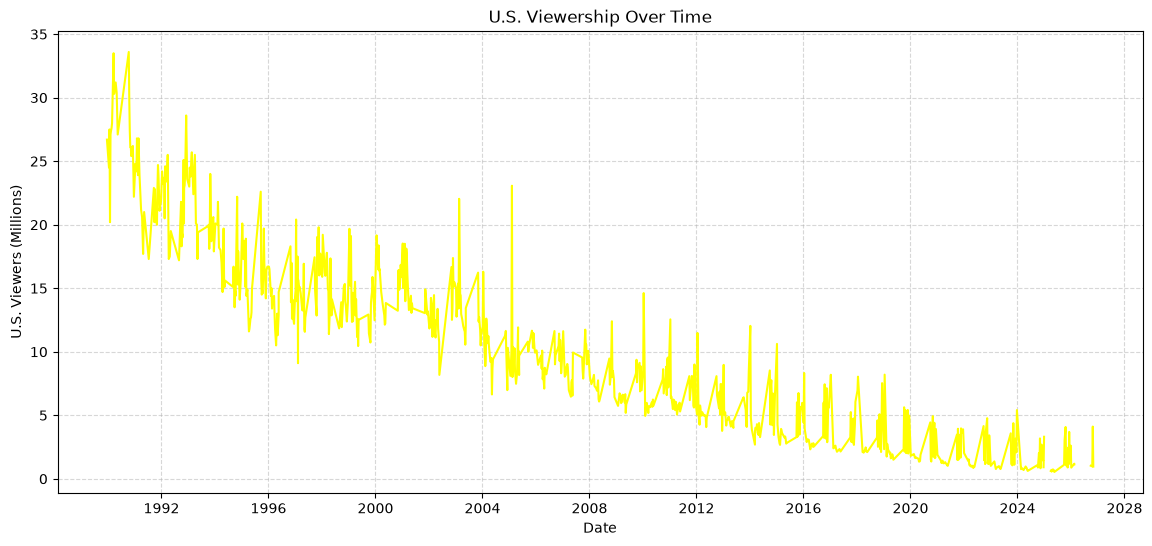

In [48]:
# Plot a graph of U.S. viewership over time
plt.figure (figsize = (14, 6))

plt.plot(
    episodes['release_date'],
    episodes['us_viewers_millions'],
    color = 'yellow'
)

plt.title('U.S. Viewership Over Time')
plt.xlabel('Date')
plt.ylabel('U.S. Viewers (Millions)')
plt.grid(linestyle = '--', alpha = 0.5)

plt.show()

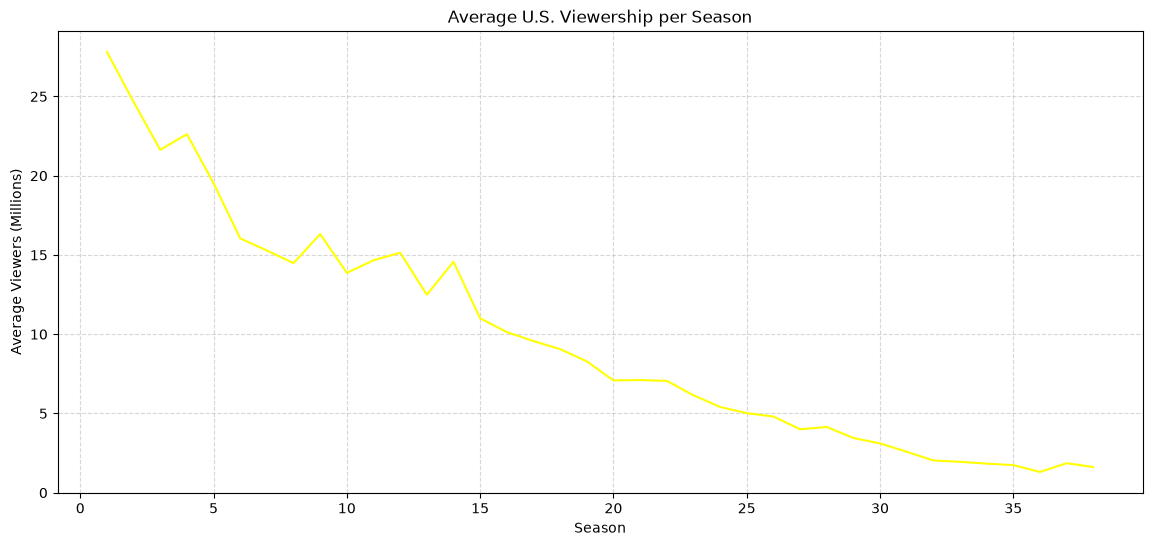

In [49]:
# Find mean viewership for each season
season_viewership = (
    episodes.groupby('season_number')['us_viewers_millions'].mean()
)

# Plot mean viewership by season
plt.figure(figsize = (14, 6))

plt.plot(season_viewership, color = 'yellow')

plt.title("Average U.S. Viewership per Season")
plt.xlabel("Season")
plt.ylabel("Average Viewers (Millions)")
plt.grid(linestyle = '--', alpha = 0.5)

plt.show()

## 4.2 IMDB Rating Trends

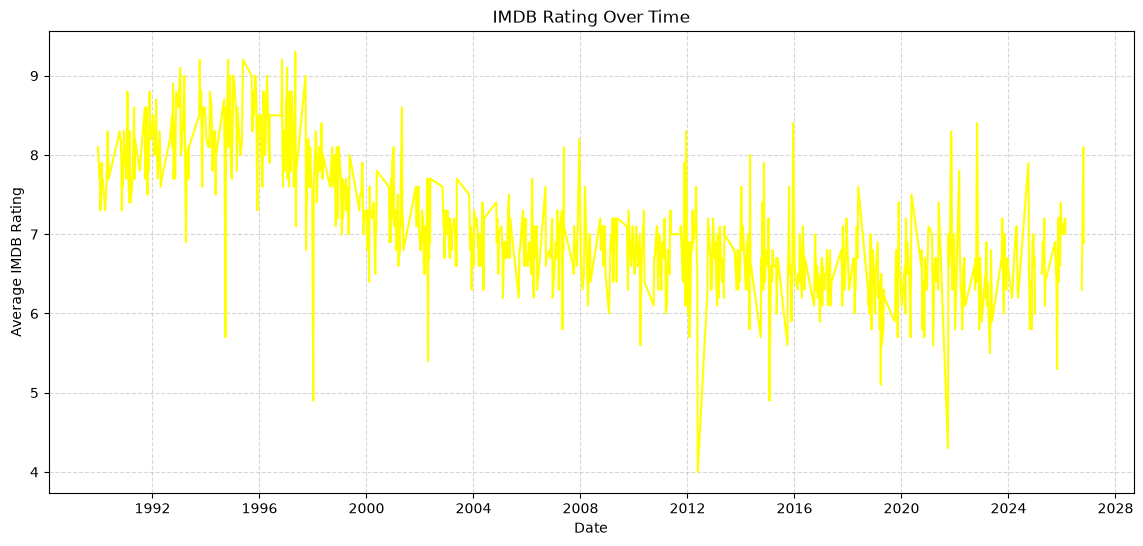

In [50]:
# Plot a graph of IMDB rating over time
plt.figure (figsize = (14, 6))

plt.plot(
    episodes['release_date'],
    episodes['average_rating'],
    color = 'yellow'
)

plt.title('IMDB Rating Over Time')
plt.xlabel('Date')
plt.ylabel('Average IMDB Rating')
plt.grid(linestyle = '--', alpha = 0.5)

plt.show()

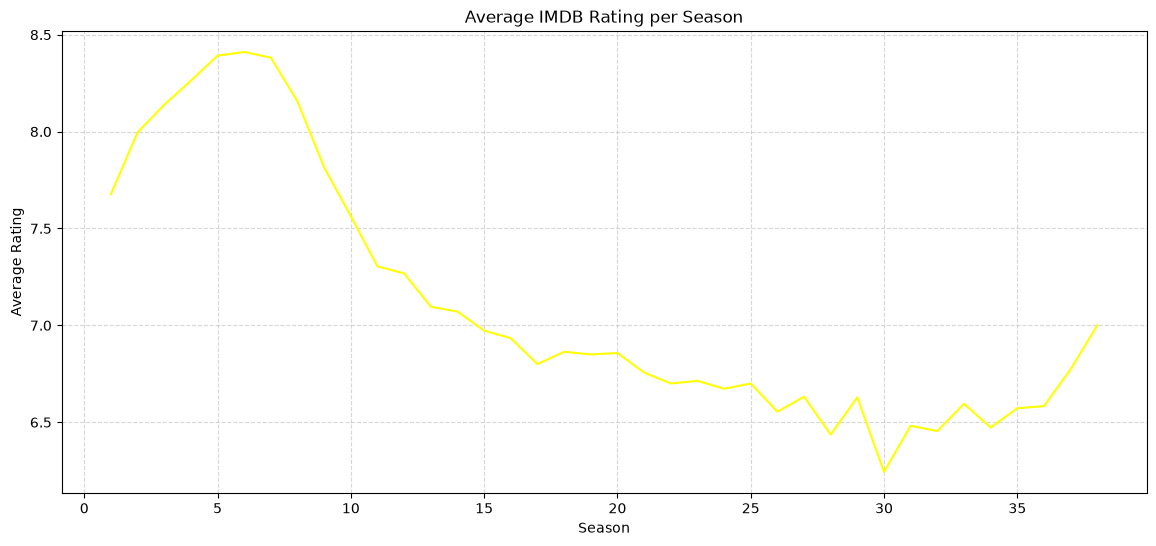

In [51]:
# Find mean IMDB rating for each season
season_rating = (
    episodes.groupby('season_number')['average_rating'].mean()
)

# Plot mean IMDB rating by season
plt.figure(figsize = (14, 6))

plt.plot(season_rating, color = 'yellow')

plt.title("Average IMDB Rating per Season")
plt.xlabel("Season")
plt.ylabel("Average Rating")
plt.grid(linestyle = '--', alpha = 0.5)

plt.show()

## 4.3 Top Writers

In [52]:
# Create individual entries for each writer for episodes with multiple writers
writers = episodes.copy()
writers = writers.explode('writer')
writers['writer'] = writers['writer'].str.strip()

writers.head()

,episode_number_overall,episode_number,title,director,writer,release_date,production_code,us_viewers_millions,season_number,average_rating,num_votes
0,1,1,"""Simpsons Roasting on an Open Fire""",[David Silverman],Mimi Pond,1989-12-17,7G08,26.7,1,8.1,10761
1,2,2,"""Bart the Genius""",[David Silverman],Jon Vitti,1990-01-14,7G02,24.5,1,7.6,7520
2,3,3,"""Homer's Odyssey""",[Wes Archer],Jay Kogen,1990-01-21,7G03,27.5,1,7.3,6711
2,3,3,"""Homer's Odyssey""",[Wes Archer],Wallace Wolodarsky,1990-01-21,7G03,27.5,1,7.3,6711
3,4,4,"""There's No Disgrace Like Home""","[Gregg Vanzo, Kent Butterworth]",Al Jean,1990-01-28,7G04,20.2,1,7.6,6489


In [53]:
# Calculate number of episodes written and average rating for each writer
writer_stats = (
    writers.groupby('writer')
    .agg(
        episodes_written = ('episode_number_overall', 'nunique'),
        average_rating = ('average_rating', 'mean'),
        total_votes = ('num_votes', 'sum')
    )
    .sort_values('episodes_written', ascending=False)
)

writer_stats.head()

,episodes_written,average_rating,total_votes
writer,,,
John Swartzwelder,58,7.893103,226146
John Frink,39,6.761538,62125
Joel H. Cohen,38,6.710526,55120
Tim Long,36,6.569444,62965
Carolyn Omine,30,6.940741,46118


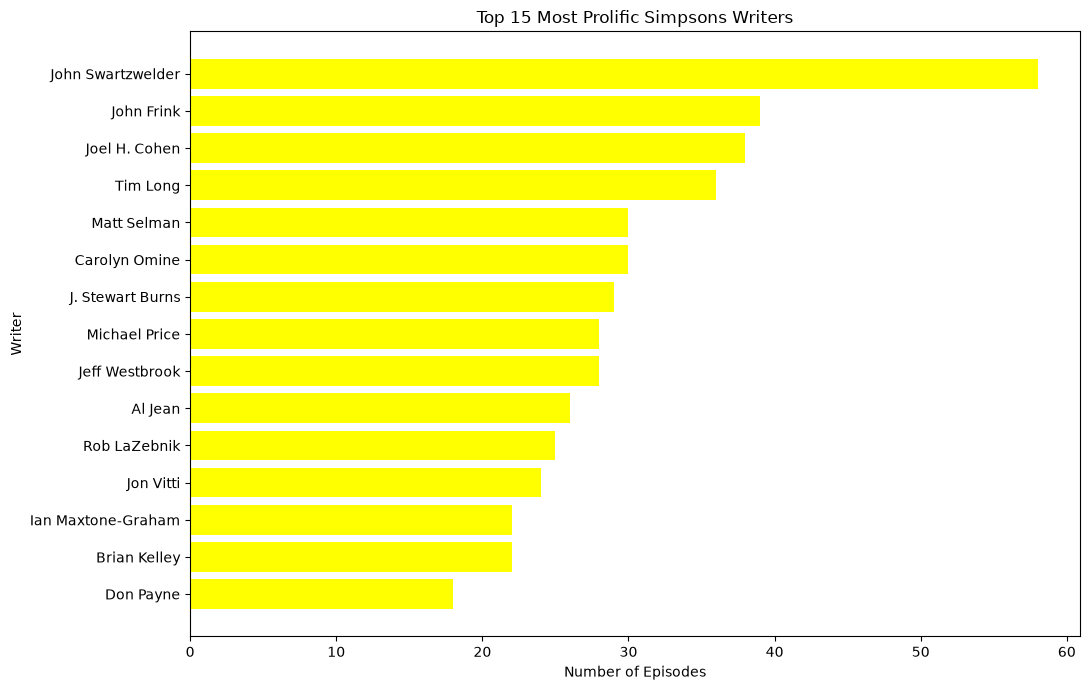

In [54]:
# Find top 15 most prolific writers
top_writers = writer_stats.head(15).sort_values('episodes_written')

# Plot top 15 most prolific writers
plt.figure(figsize = (11, 7))

plt.barh(
    top_writers.index,
    top_writers['episodes_written'],
    color = 'yellow'
)

plt.title('Top 15 Most Prolific Simpsons Writers')
plt.xlabel('Number of Episodes')
plt.ylabel('Writer')

plt.tight_layout()
plt.show()

In [55]:
# Calculate the writers with the highest average IMDB rating
top_rated_writers = (
    writer_stats[writer_stats['episodes_written'] >=5]
    .sort_values('average_rating', ascending = False)
    .head(15)
)

top_rated_writers

,episodes_written,average_rating,total_votes
writer,,,
Greg Daniels,8,8.675000,38196
Josh Weinstein,13,8.353846,56372
Bill Oakley,13,8.353846,56372
Jonathan Collier,6,8.333333,23197
Jennifer Crittenden,5,8.260000,19865
David X. Cohen,13,8.215385,48550
Ken Keeler,6,8.200000,24558
Richard Appel,7,8.157143,25863
Jay Kogen,10,8.030000,53047


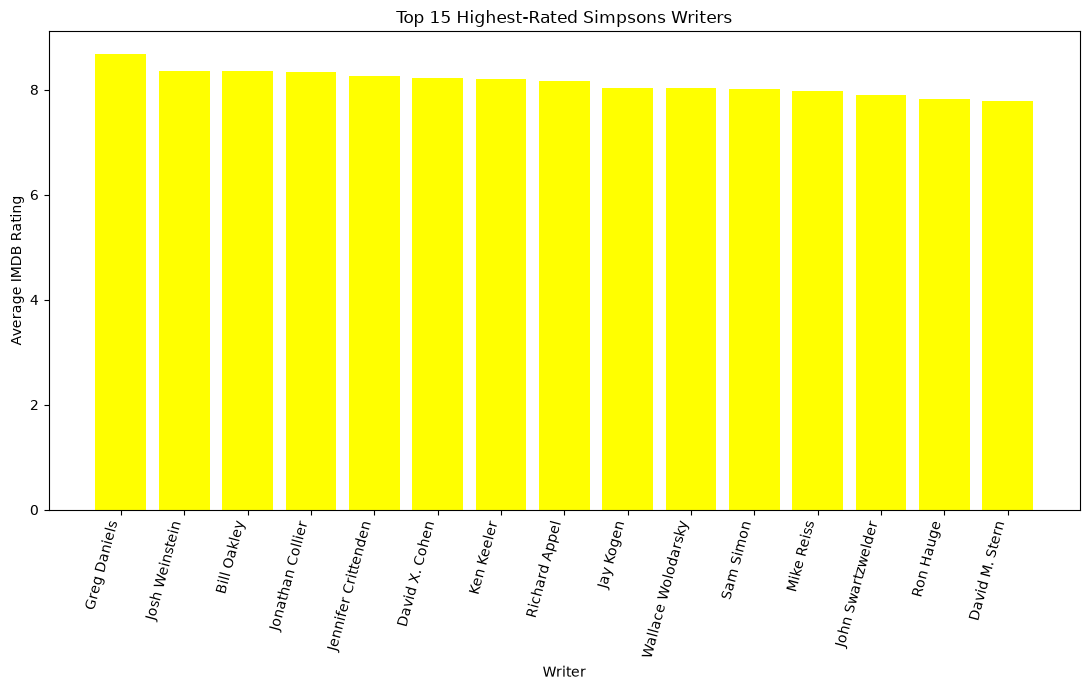

In [56]:
# Plot top 15 highest-rated Simpsons writers
plt.figure(figsize = (11, 7))

plt.bar(
    top_rated_writers.index,
    top_rated_writers['average_rating'],
    color = 'yellow'
)

plt.title('Top 15 Highest-Rated Simpsons Writers')
plt.xlabel('Writer')
plt.ylabel('Average IMDB Rating')
plt.xticks(rotation = 75, ha ='right')

plt.tight_layout()
plt.show()

## 4.4 Top Directors

In [57]:
# Create individual entries for each director for episodes with multiple directors
directors = episodes.copy()
directors = directors.explode('director')
directors['director'] = directors['director'].str.strip()

directors.head()

,episode_number_overall,episode_number,title,director,writer,release_date,production_code,us_viewers_millions,season_number,average_rating,num_votes
0,1,1,"""Simpsons Roasting on an Open Fire""",David Silverman,[Mimi Pond],1989-12-17,7G08,26.7,1,8.1,10761
1,2,2,"""Bart the Genius""",David Silverman,[Jon Vitti],1990-01-14,7G02,24.5,1,7.6,7520
2,3,3,"""Homer's Odyssey""",Wes Archer,"[Jay Kogen, Wallace Wolodarsky]",1990-01-21,7G03,27.5,1,7.3,6711
3,4,4,"""There's No Disgrace Like Home""",Gregg Vanzo,"[Al Jean, Mike Reiss]",1990-01-28,7G04,20.2,1,7.6,6489
3,4,4,"""There's No Disgrace Like Home""",Kent Butterworth,"[Al Jean, Mike Reiss]",1990-01-28,7G04,20.2,1,7.6,6489


In [58]:
# Calculate number of episodes directed and average rating for each director
director_stats = (
    directors.groupby('director')
    .agg(
        episodes_directed = ('episode_number_overall', 'nunique'),
        average_rating = ('average_rating', 'mean'),
        total_votes = ('num_votes', 'sum')
    )
    .sort_values('episodes_directed', ascending=False)
)

director_stats.head()

,episodes_directed,average_rating,total_votes
director,,,
Steven Dean Moore,87,6.920225,172251
Mark Kirkland,84,7.311628,231860
Matthew Nastuk,68,6.688406,105099
Bob Anderson,66,6.977143,142561
Mike Frank Polcino,45,6.555814,60643


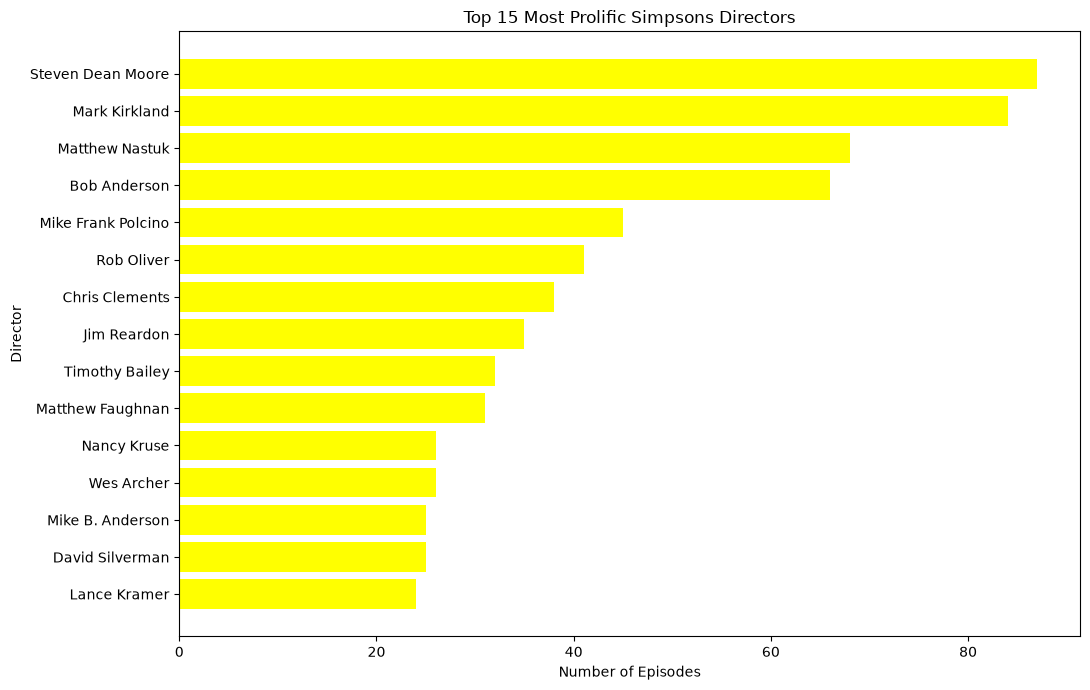

In [59]:
#Calculate top 15 most prolific directors
top_directors = director_stats.head(15).sort_values('episodes_directed')

# plot top 15 most prolific directors
plt.figure(figsize = (11, 7))

plt.barh(
    top_directors.index,
    top_directors['episodes_directed'],
    color = 'yellow'
)

plt.title('Top 15 Most Prolific Simpsons Directors')
plt.xlabel('Number of Episodes')
plt.ylabel('Director')

plt.tight_layout()
plt.show()

In [60]:
# Calculate the directors with the highest average IMDB rating
top_rated_directors = (
    director_stats[director_stats['episodes_directed'] >=5]
    .sort_values('average_rating', ascending = False)
    .head(15)
)

top_rated_directors

,episodes_directed,average_rating,total_votes
director,,,
Rich Moore,16,8.312500,85394
Jeffrey Lynch,12,8.300000,52333
Jim Reardon,35,8.241463,181763
Wes Archer,26,8.184615,126165
Carlos Baeza,9,8.181818,49370
Swinton O. Scott III,7,8.100000,24314
Susie Dietter,11,8.009091,38063
David Silverman,25,7.826667,134299
Dominic Polcino,7,7.814286,22141


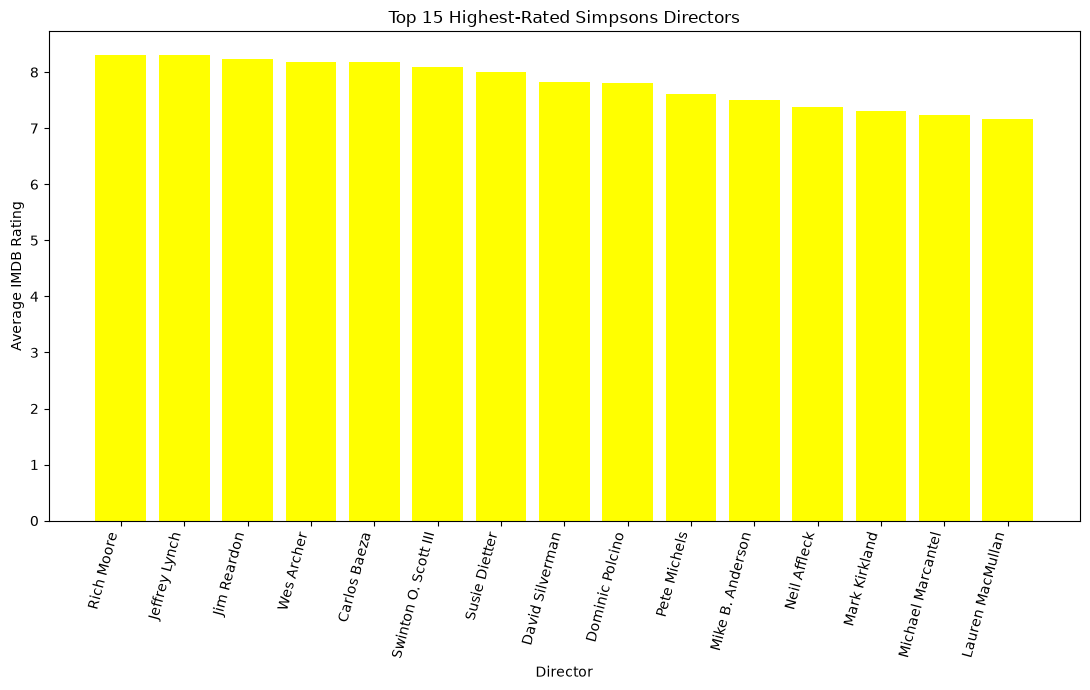

In [61]:
# Plot top 15 highest-rated Simpsons directors
plt.figure(figsize = (11, 7))

plt.bar(
    top_rated_directors.index,
    top_rated_directors['average_rating'],
    color = 'yellow'
)

plt.title('Top 15 Highest-Rated Simpsons Directors')
plt.xlabel('Director')
plt.ylabel('Average IMDB Rating')
plt.xticks(rotation = 75, ha = 'right')

plt.tight_layout()
plt.show()

# 5. Key Findings

# 6. Conclusion

In [62]:
# Find episode with highest number of U.S. viewers
episodes[['title', 'season_number', 'episode_number']][episodes['us_viewers_millions'] == episodes['us_viewers_millions'].max()]

,title,season_number,episode_number
13,"""Bart Gets an 'F'""",2,1


In [63]:
# Find episode with highest IMDB rating
episodes[['title', 'season_number', 'episode_number']][episodes['average_rating'] == episodes['average_rating'].max()]

,title,season_number,episode_number
197,"""Homer's Enemy""",8,23
